# Systemy AI – Laboratorium 5
## Zadanie: który klasyfikator najlepiej rozpoznaje cukrzycę?

Zbiór **Pima Indians Diabetes**: 768 kobiet z plemienia Pima (Arizona, USA). Zadanie: na podstawie wyników badań przewidzieć, czy u pacjentki zdiagnozowano cukrzycę w ciągu 5 lat (`outcome` = 1).

Wykonaj całą procedurę z notatnika `SystemyAI_Lab5_Titanic_CV.ipynb`: porównaj klasyfikatory walidacją krzyżową, dostrój hiperparametry, wybierz najlepszy model i **dopiero na końcu, raz**, oceń go na zbiorze testowym. Cały kod piszesz sam(a).

| Kolumna | Znaczenie |
|---|---|
| `pregnancies` | liczba ciąż |
| `glucose` | stężenie glukozy po 2 h w doustnym teście obciążenia glukozą [mg/dl] |
| `blood_pressure` | ciśnienie rozkurczowe [mm Hg] |
| `skin_thickness` | grubość fałdu skórnego na tricepsie [mm] |
| `insulin` | stężenie insuliny po 2 h [μU/ml] |
| `bmi` | wskaźnik masy ciała [kg/m²] |
| `pedigree` | wskaźnik obciążenia rodzinnego cukrzycą |
| `age` | wiek [lata] |
| `outcome` | **etykieta**: 1 = cukrzyca, 0 = brak |

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie danych
Plik nie ma wiersza nagłówka, więc nazwy kolumn trzeba podać samemu:

```python
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
```
Zaimportuj potrzebne biblioteki, wczytaj dane do `df` i obejrzyj je (`shape`, `head()`, `describe()`).

In [ ]:
# Twoje rozwiązanie
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
df = pd.read_csv("https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv", names=["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin", "bmi", "pedigree", "age", "outcome"])
df.head()

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
# TEST
assert df.shape == (768, 9) and list(df.columns)[-1] == "outcome"
print("1 OK")

1 OK


---
## 2. EDA i ukryte braki
1. `class_share` – udział każdej klasy w `outcome`.
2. `df.isna().sum()` – czy są braki? Teraz policz `zeros` – liczbę **zer** w każdej kolumnie cech.
3. Narysuj `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`: po lewej histogram `glucose`, po prawej histogram `insulin`, oba z kolorem według `outcome` (`sns.histplot(..., hue="outcome")`).

<Axes: xlabel='insulin', ylabel='Count'>

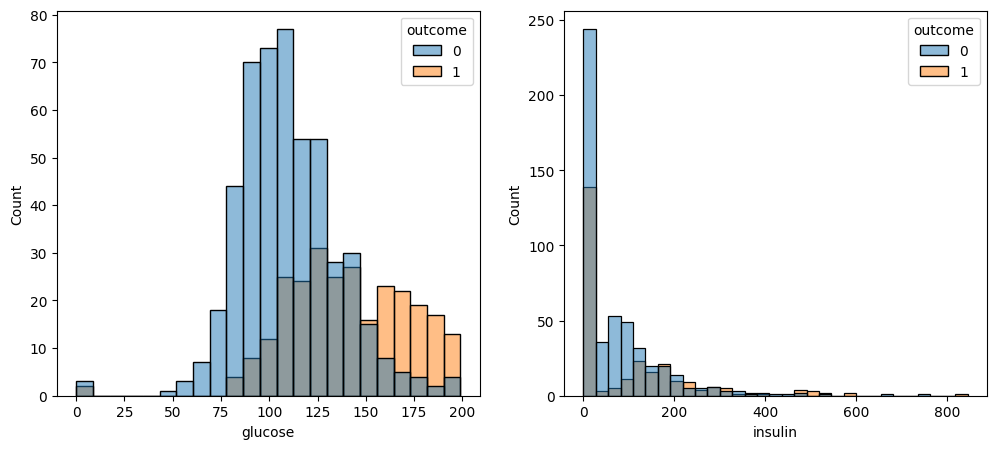

In [ ]:
# Twoje rozwiązanie
class_share = df["outcome"].value_counts(normalize=True)
zeros = (df == 0).sum()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="glucose", hue="outcome", ax=axes[0])
sns.histplot(data=df, x="insulin", hue="outcome", ax=axes[1])


In [ ]:
# TEST
assert abs(class_share[0] - 0.651) < 1e-3
assert zeros["insulin"] == 374 and zeros["glucose"] == 5 and zeros["pregnancies"] == 111
print("2 OK")

2 OK


*Twoja odpowiedź:*
1. Jaką accuracy osiągnie baseline?
2. W których kolumnach zero jest **fizycznie niemożliwe** (żyjący człowiek nie może mieć takiej wartości), a w której jest zupełnie normalne?
3. Która cecha najwyraźniej różni chore i zdrowe pacjentki?

---
## 3. Zamiana ukrytych braków na `NaN`
W kolumnach `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, `bmi` zamień zera na `np.nan` (`replace(0, np.nan)`). Wynik zapisz w `df_clean` (kopia `df`), a liczbę braków w każdej kolumnie w `missing`.

Model nie wie, że zero oznacza brak. Dla niego „insulina = 0” to po prostu bardzo niska insulina – a takich „pomiarów” jest prawie połowa.

In [ ]:
# Twoje rozwiązanie
df_clean = df.copy()
kolumny_z_brakami = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
df_clean[kolumny_z_brakami] = df_clean[kolumny_z_brakami].replace(0, np.nan)
missing = df_clean.isna().sum()


In [ ]:
# TEST
assert missing["insulin"] == 374 and missing["skin_thickness"] == 227 and missing["pregnancies"] == 0
assert (df["insulin"] == 0).sum() == 374, "Nie zmieniaj oryginalnego df - użyj copy()"
print("3 OK")

3 OK


*Twoja odpowiedź:* insuliny brakuje u prawie połowy pacjentek. Jakie masz możliwości? Co wybierasz i dlaczego?

---
## 4. Podział i przygotowanie
1. `X` – wszystkie cechy z `df_clean`, `y` – `outcome`. Podziel na `X_train, X_test, y_train, y_test` (`test_size=0.25`, `stratify=y`, `random_state=42`).
2. Napisz funkcję `model_z(klasyfikator)`, która zwraca pipeline: `SimpleImputer(strategy="median")` → `StandardScaler()` → klasyfikator. (Wszystkie cechy są liczbowe, więc `ColumnTransformer` nie jest potrzebny.)
3. Utwórz `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

In [ ]:
# Twoje rozwiązanie
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold

def model_z(klasyfikator):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), klasyfikator)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X = df_clean.drop(columns=["outcome"])
y = df_clean["outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

In [ ]:
# TEST
assert X_train.shape == (576, 8) and X_test.shape == (192, 8)
assert X_train["insulin"].isna().sum() > 0, "Podział robimy na df_clean (z NaN zamiast zer)"
assert len(model_z(None).steps) == 3
print("4 OK")

4 OK


---
## 5. Porównanie klasyfikatorów walidacją krzyżową
Dla pięciu modeli z domyślnymi hiperparametrami: `DummyClassifier(strategy="most_frequent")`, `LogisticRegression()`, `KNeighborsClassifier()`, `DecisionTreeClassifier(random_state=42)`, `RandomForestClassifier(random_state=42)` policz `cross_val_score` na zbiorze treningowym i accuracy na całym zbiorze treningowym.

Zbierz wyniki w tabeli `porownanie` (indeks: `"baseline"`, `"regresja logistyczna"`, `"kNN"`, `"drzewo decyzyjne"`, `"las losowy"`; kolumny: `"CV średnia"`, `"CV odch."`, `"train"`) i narysuj wykres słupkowy średnich z odchyleniami.

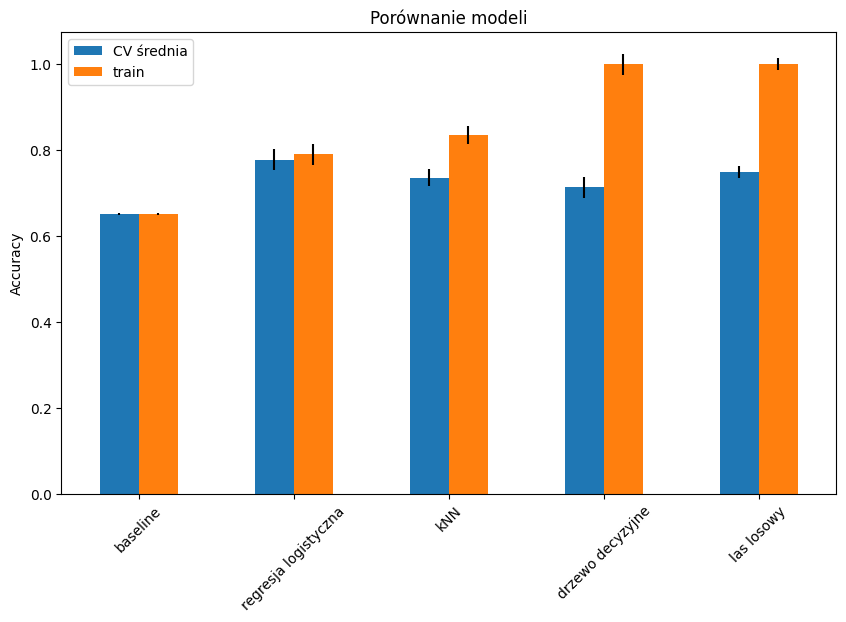

In [ ]:
# Twoje rozwiązanie
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Definicja słownika z modelami
modele = {
    "baseline": DummyClassifier(strategy="most_frequent"),
    "regresja logistyczna": LogisticRegression(max_iter=1000),
    "kNN": KNeighborsClassifier(),
    "drzewo decyzyjne": DecisionTreeClassifier(random_state=42),
    "las losowy": RandomForestClassifier(random_state=42)
}

# Inicjalizacja DataFrame
porownanie = pd.DataFrame(columns=["CV średnia", "CV odch.", "train"], index=modele.keys())

for nazwa, model in modele.items():
    # Tworzymy pipeline za pomocą funkcji model_z
    pipeline = model_z(model)

    # Walidacja krzyżowa (CV)
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="accuracy")
    porownanie.loc[nazwa, "CV średnia"] = scores.mean()
    porownanie.loc[nazwa, "CV odch."] = scores.std()

    # Trening i accuracy na całym zbiorze treningowym
    pipeline.fit(X_train, y_train)
    porownanie.loc[nazwa, "train"] = pipeline.score(X_train, y_train)

# Opcjonalnie: narysowanie wykresu
import matplotlib.pyplot as plt
porownanie[["CV średnia", "train"]].plot(kind="bar", yerr=porownanie["CV odch."].to_list(), figsize=(10, 6))
plt.title("Porównanie modeli")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.show()

In [ ]:
# TEST
assert list(porownanie.index) == ["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"]
assert abs(porownanie.loc["baseline", "CV średnia"] - 0.651) < 1e-2
assert abs(porownanie.loc["regresja logistyczna", "CV średnia"] - 0.778) < 1e-2
assert porownanie.loc["drzewo decyzyjne", "train"] > 0.99
print("5 OK")

5 OK


---
## 6. Krzywa walidacji dla kNN
Policz `validation_curve` dla `kneighborsclassifier__n_neighbors` w `ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]`. Wyniki zapisz w `tren`, `walid`; narysuj średnie (trening i walidacja) w funkcji k.

In [ ]:
# Twoje rozwiązanie
from sklearn.model_selection import validation_curve

ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]
tren, walid = validation_curve(model_z(KNeighborsClassifier()), X_train, y_train, param_name="kneighborsclassifier__n_neighbors", param_range=ks, cv=cv)


In [ ]:
# TEST
assert tren.shape == (9, 5) and walid.shape == (9, 5)
assert tren.mean(axis=1)[0] == 1.0, "Dla k=1 wynik treningowy powinien wynosić 1.0"
print("6 OK")

6 OK


*Twoja odpowiedź:* dlaczego dla k = 1 wynik treningowy wynosi dokładnie 1.0? Gdzie jest przeuczenie, a gdzie niedouczenie?

---
## 7. Strojenie: `GridSearchCV`
Dla każdego z czterech klasyfikatorów uruchom `GridSearchCV(model_z(...), siatka, cv=cv)` na zbiorze treningowym. Siatki:
- regresja logistyczna: `C` ∈ {0.01, 0.1, 1, 10, 100},
- kNN: `n_neighbors` ∈ {1, 3, 5, 7, 11, 15, 21, 31},
- drzewo: `max_depth` ∈ {2, 3, 4, 5, 6, 8, None},
- las losowy: `max_depth` ∈ {3, 5, 8, None}, `n_estimators` ∈ {100, 300}.

Nauczone obiekty zapisz w słowniku `wyniki_gs` (klucze jak w punkcie 5, bez baseline'u) i wypisz najlepsze parametry oraz `best_score_` każdego modelu.

In [ ]:
# Twoje rozwiązanie
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

wyniki_gs = {}
siatki = {
    "regresja logistyczna": (LogisticRegression(max_iter=1000), {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "kNN": (KNeighborsClassifier(), {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]}),
    "drzewo decyzyjne": (DecisionTreeClassifier(random_state=42), {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6, 8, None]}),
    "las losowy": (RandomForestClassifier(random_state=42), {"randomforestclassifier__max_depth": [3, 5, 8, None], "randomforestclassifier__n_estimators": [100, 300]})
}

for model_name, (clf, siatka) in siatki.items():
    gs = GridSearchCV(model_z(clf), siatka, cv=cv)
    gs.fit(X_train, y_train)
    wyniki_gs[model_name] = gs
    print(f"Najlepsze parametry dla {model_name}: {gs.best_params_}")
    print(f"Najlepszy wynik dla {model_name}: {gs.best_score_}")


Najlepsze parametry dla regresja logistyczna: {'logisticregression__C': 1}
Najlepszy wynik dla regresja logistyczna: 0.777856071964018
Najlepsze parametry dla kNN: {'kneighborsclassifier__n_neighbors': 15}
Najlepszy wynik dla kNN: 0.7778110944527736
Najlepsze parametry dla drzewo decyzyjne: {'decisiontreeclassifier__max_depth': 5}
Najlepszy wynik dla drzewo decyzyjne: 0.7499700149925037
Najlepsze parametry dla las losowy: {'randomforestclassifier__max_depth': 3, 'randomforestclassifier__n_estimators': 300}
Najlepszy wynik dla las losowy: 0.76215892053973


In [ ]:
# TEST
assert set(wyniki_gs) == {"regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"}
assert all(hasattr(gs, "best_estimator_") for gs in wyniki_gs.values())
assert all(gs.best_score_ > 0.7 for gs in wyniki_gs.values())
print("7 OK")

7 OK


---
## 8. Wybór modelu i ocena końcowa
1. `najlepszy` – nazwa modelu z najwyższym `best_score_`; `model_koncowy` – jego `best_estimator_`.
2. `acc_test` – accuracy `model_koncowy` na zbiorze testowym (**jedyny raz, kiedy używasz `X_test`**).
3. Macierz pomyłek (`ConfusionMatrixDisplay`) i `classification_report`.

In [ ]:
# Twoje rozwiązanie
najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_
y_pred = model_koncowy.predict(X_test)
acc_test = model_koncowy.score(X_test, y_test)
print(f"Najlepszy model: {najlepszy}")
print(f"Accuracy na zbiorze testowym: {acc_test}")

Najlepszy model: regresja logistyczna
Accuracy na zbiorze testowym: 0.7239583333333334


In [ ]:
# TEST
assert najlepszy == max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
assert 0.65 < acc_test < 0.9
print("8 OK")

8 OK


*Twoja odpowiedź:*
1. Jak wynik testowy ma się do szacunku z walidacji krzyżowej? Czy różnica cię niepokoi? (Zbiór testowy ma 192 pacjentki – ile p.p. to jedna osoba?)
2. Jaki jest recall dla klasy „cukrzyca”? Co oznacza on dla pacjentek? Czy accuracy to dobra metryka do wyboru modelu w tym zastosowaniu?
3. Modele w czołówce różnią się w CV o 1–2 p.p., a odchylenia wynoszą ok. 2–3 p.p. Czy można jednoznacznie wskazać „najlepszy” algorytm?

---
## 9. Dla chętnych
1. Powtórz punkty 7–8 z `scoring="recall"` w `GridSearchCV`. Czy zmienił się wybrany model? Co stało się z precision?
2. Dodaj do imputera `add_indicator=True` (flagi braków). Czy sam fakt braku pomiaru insuliny niesie informację?
3. Sprawdź, jak wyglądałyby wyniki, gdyby zostawić zera zamiast `NaN` (punkt 3 pominięty). Czy różnica jest duża? Dlaczego może być mała?

In [ ]:
wyniki_gs2 ={}
siatki2 = {
    "regresja logistyczna": (LogisticRegression(max_iter=1000), {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "kNN": (KNeighborsClassifier(), {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]}),
    "drzewo decyzyjne": (DecisionTreeClassifier(random_state=42), {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6, 8, None]}),
    "las losowy": (RandomForestClassifier(random_state=42), {"randomforestclassifier__max_depth": [3, 5, 8, None], "randomforestclassifier__n_estimators": [100, 300]})
}
for model_name, (clf, siatka) in siatki2.items():
    gs = GridSearchCV(model_z(clf), siatka, cv=cv, scoring="recall")
    gs.fit(X_train, y_train)
    wyniki_gs2[model_name] = gs
    print(f"Najlepsze parametry dla {model_name}: {gs.best_params_}")
    print(f"Najlepszy wynik dla {model_name}: {gs.best_score_}")
najlepszy2 = max(wyniki_gs2, key=lambda n: wyniki_gs2[n].best_score_)
model_koncowy2 = wyniki_gs2[najlepszy2].best_estimator_
y_pred2 = model_koncowy2.predict(X_test)
acc_test2 = model_koncowy2.score(X_test, y_test)
print(f"Najlepszy model: {najlepszy2}")
print(f"Accuracy na zbiorze testowym: {acc_test2}")

Najlepsze parametry dla regresja logistyczna: {'logisticregression__C': 1}
Najlepszy wynik dla regresja logistyczna: 0.5825609756097561
Najlepsze parametry dla kNN: {'kneighborsclassifier__n_neighbors': 3}
Najlepszy wynik dla kNN: 0.5971951219512196
Najlepsze parametry dla drzewo decyzyjne: {'decisiontreeclassifier__max_depth': 4}
Najlepszy wynik dla drzewo decyzyjne: 0.6517073170731708
Najlepsze parametry dla las losowy: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__n_estimators': 100}
Najlepszy wynik dla las losowy: 0.5823170731707317
Najlepszy model: drzewo decyzyjne
Accuracy na zbiorze testowym: 0.75


In [ ]:
wyniki_gs3 = {}
siatki3 = {
    "regresja logistyczna": (LogisticRegression(max_iter=1000), {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "kNN": (KNeighborsClassifier(), {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]}),
    "drzewo decyzyjne": (DecisionTreeClassifier(random_state=42), {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6, 8, None]}),
    "las losowy": (RandomForestClassifier(random_state=42), {"randomforestclassifier__max_depth": [3, 5, 8, None], "randomforestclassifier__n_estimators": [100, 300]})
}

# Tworzymy funkcję pomocniczą z imputacją uwzględniającą wskaźnik braków (add_indicator=True)
def model_z_indikatorem(klasyfikator):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), klasyfikator)

for model_name, (clf, siatka) in siatki3.items():
    # Używamy zmodyfikowanego potoku z add_indicator=True
    gs = GridSearchCV(model_z_indikatorem(clf), siatka, cv=cv)
    gs.fit(X_train, y_train)
    wyniki_gs3[model_name] = gs
    print(f"Najlepsze parametry dla {model_name}: {gs.best_params_}")
    print(f"Najlepszy wynik dla {model_name}: {gs.best_score_}")

najlepszy3 = max(wyniki_gs3, key=lambda n: wyniki_gs3[n].best_score_)
model_koncowy3 = wyniki_gs3[najlepszy3].best_estimator_
y_pred3 = model_koncowy3.predict(X_test)
acc_test3 = model_koncowy3.score(X_test, y_test)
print(f"\nNajlepszy model: {najlepszy3}")
print(f"Accuracy na zbiorze testowym: {acc_test3}")

Najlepsze parametry dla regresja logistyczna: {'logisticregression__C': 0.1}
Najlepszy wynik dla regresja logistyczna: 0.7691304347826087
Najlepsze parametry dla kNN: {'kneighborsclassifier__n_neighbors': 11}
Najlepszy wynik dla kNN: 0.7569265367316341
Najlepsze parametry dla drzewo decyzyjne: {'decisiontreeclassifier__max_depth': 5}
Najlepszy wynik dla drzewo decyzyjne: 0.7517091454272864
Najlepsze parametry dla las losowy: {'randomforestclassifier__max_depth': 8, 'randomforestclassifier__n_estimators': 100}
Najlepszy wynik dla las losowy: 0.7586956521739131

Najlepszy model: regresja logistyczna
Accuracy na zbiorze testowym: 0.7291666666666666
